<a href="https://colab.research.google.com/github/group6aiml-hub/NIDS_AInML/blob/notebooks/notebooks/04_multiclass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Loading in CLean data

from google.colab import drive
drive.mount('/content/drive')



import pandas as pd
import numpy as np

path = '/content/drive/MyDrive/Datasets/'
train = pd.read_csv(path + 'train_clean.csv')
test  = pd.read_csv(path + 'test_clean.csv')
print(train.shape, test.shape)

Mounted at /content/drive
(107740, 43) (82332, 43)


In [ ]:
#Skill ut X somer features og Y somer fasit

X_train = train.drop(columns=['label', 'attack_cat'])
y_train = train['attack_cat']
X_test  = test.drop(columns=['label', 'attack_cat'])
y_test  = test['attack_cat']

#Hvorfor: modellen skal lære å gjette svaret, så svaret kan ikke ligge blant features.
#attack_cat må også ut av X: den avslører svaret direkte, fordi alt som ikke er “Normal” er et angrep.

In [ ]:
#Del train i trening og validering

from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

#Hvorfor: vi skal ta mange valg (modell, innstillinger, features).
#Valgene tas ut fra valideringssettet. Testsettet røres ikke før helt til slutt,
#ellers tilpasser vi oss testsettet og får for gode resultater.

#stratify=y_train gir lik andel angrep og normal i begge delene.
#random_state=42 gjør at alle får samme oppdeling.

In [ ]:
#Del kolonnene i grupper

cat_cols = ['proto', 'service', 'state']
num_cols = X_tr.columns.drop(cat_cols).tolist()

skew = X_tr[num_cols].skew()
skew_cols  = skew[skew.abs() > 1].index.tolist()
other_cols = [c for c in num_cols if c not in skew_cols]

print(len(cat_cols), len(skew_cols), len(other_cols))

#Hvorfor: de tre typene kolonner trenger ulik behandling:
# -Kategoriske (tekst) må gjøres om til tall.
# -Skjeve tallkolonner trenger log-transformasjon før skalering.
# -Øvrige tallkolonner trenger bare skalering.

#Skjevheten beregnes bare på X_tr, altså treningsdelen.

3 32 6


In [ ]:
# Bygg preprossesering

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

preprocess = ColumnTransformer([
    ('cat',  OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('skew', Pipeline([('log',   FunctionTransformer(np.log1p)),
                       ('scale', StandardScaler())]), skew_cols),
    ('num',  StandardScaler(), other_cols),
])

# Hva hver del gjør:

#OneHotEncoder: gjør hver kategori til en egen 0/1-kolonne.
#handle_unknown='ignore' er en ekstra sikring mot ukjente verdier.

#log1p + StandardScaler: demper ekstreme verdier og setter alle features på samme skala.

#ColumnTransformer: sender hver kolonnegruppe til riktig behandling og setter resultatet sammen igjen.

In [ ]:
# More Imports

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


In [ ]:
#tren Random forest

rf_multi = Pipeline([
    ('prep', preprocess),
    ('clf',  RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
rf_multi.fit(X_tr, y_tr)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['proto', 'service',
                                                   'state']),
                                                 ('skew',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['dur', 'spkts', 'dpkts',
                                                   'sbytes', 'dbytes', 'rate',
                                                   'sload', 'dload', 'sloss',
                                                   'dloss', 'sinpkt', 'dinpkt',
                                                   'sjit', 'djit', 'tcprtt',
                                                   'synack', 'ackdat', 'smean',
                                                   'dmean', 'trans_depth',
                                                   'response_body_len',
                                                   'ct_srv_src', 'ct_state_ttl',
                                                   'ct_dst_ltm',
                                                   'ct_src_dport_ltm',
                                                   'ct_dst_sport_ltm',
                                                   'ct_dst_src_ltm',
                                                   'ct_ftp_cmd',
                                                   'ct_flw_http_mthd',
                                                   'ct_src_ltm', ...]),
                                                 ('num', StandardScaler(),
                                                  ['sttl', 'dttl', 'swin',
                                                   'stcpb', 'dtcpb',
                                                   'dwin'])])),
                ('clf', RandomForestClassifier(n_jobs=-1, random_state=42))])

                precision    recall  f1-score   support

      Analysis      0.058     0.053     0.055       319
      Backdoor      0.198     0.169     0.183       307
           DoS      0.356     0.197     0.254       761
      Exploits      0.780     0.867     0.821      3969
       Fuzzers      0.681     0.746     0.712      3230
       Generic      0.921     0.818     0.866       836
        Normal      0.940     0.921     0.930     10378
Reconnaissance      0.749     0.735     0.742      1504
     Shellcode      0.635     0.670     0.652       218
         Worms      0.625     0.192     0.294        26

      accuracy                          0.815     21548
     macro avg      0.594     0.537     0.551     21548
  weighted avg      0.810     0.815     0.811     21548



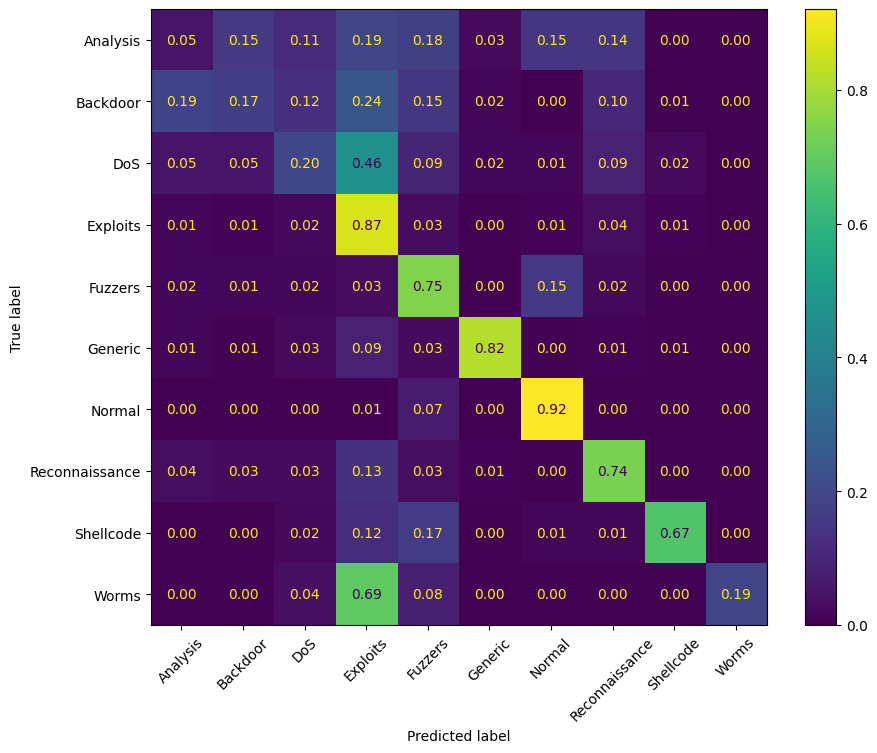

In [ ]:
#Evaluer
y_pred = rf_multi.predict(X_val)
print(classification_report(y_val, y_pred, digits=3, zero_division=0))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred, ax=ax,
                                        xticks_rotation=45, normalize='true',
                                        values_format='.2f')

## Multiklasse-baseline: Random Forest (valideringssett)

**Macro-F1: 0.551** (binær: 0.910) · Accuracy: 0.815

- **Gode klasser:** Normal (F1 0.93), Generic (0.87), Exploits (0.82)
- **Svake klasser:** Analysis (0.06), Backdoor (0.18), DoS (0.25), Worms (0.29)
- **Exploits fungerer som "sluk":** 46 % av DoS og 69 % av Worms klassifiseres som Exploits.
- **15 % av Fuzzers klassifiseres som Normal**, altså oversette angrep.
- Analysis og Backdoor har ca. 75 % rader med motstridende merkelapper (se rensing). Dette forklarer den svært lave ytelsen.
- Worms har bare 26 rader i valideringen, så tallene er usikre.

**Hypotese for ubalanse-eksperimentene:** tiltak vil forbedre Worms og delvis DoS, men ikke Analysis og Backdoor.
